# What does each saved Qwen update do to the decomposition, and can a random change tell?

*E57, Stages A to C, 2026-10-30. Record and full tables: `reports/analyses/2026-10-30_analysis_e57-reading-the-update.md`.
Plan: `reports/plans/2026-10-30_plan_q3-reading-the-update.md`. Words as in `GOALS.md` → Terms. Stage D has not run.*

## The answer

The share of each update's effect that Γ recovers by switching subcomponents is about one for every change we tried,
random ones included, so it says nothing about the update. What does separate updates from random changes is the
direct share: what the split subcomponents carry at the original masks. The two maths fine-tunes read 0.06 and 0.09.
The random changes read 0.02 to 0.03. But the maths fine-tunes are also the largest changes, and among real updates
the direct share rises with size, so size may explain the gap.

## What we were trying to test

Qwen3-1.7B has a parameter decomposition: each weight matrix is a sum of rank-one subcomponents plus a remainder Δ.
A gate network Γ reads the activations and gives each subcomponent a mask value between 0 and 1. A fine-tune moves
the weights by δW. The least-squares split writes δW as small changes to each subcomponent's read and write vectors.

We read six weight changes, all on the same 128 maths rows of 256 tokens:

- **E40 gold, step 10** and **E45 gold, step 100**: full fine-tunes on human GSM8K solutions.
- **Anchor 2, two seeds**: 100 steps on invented facts the model cannot know.
- **Two random changes**: a Gaussian δW, mostly outside the subcomponents' span, and a random change to the alive
  subcomponents themselves. They rule out "any change of this size reads like this".

Their sizes differ. On one yardstick read on the same rows for all six, K00 − K0, gold is 1.7 to 2.3 times the random
changes. Anchor 2 is matched in size to the alive-pieces change.

With Δ switched off we measure the mean per-token KL from the changed model to the CI-masked original-weights model.
The masked model uses either the original or the split subcomponents, with masks from Γ run on either the original
model's activations or the changed model's. The **re-gating share** is the fraction of the masked model's error removed
by changing only the masks. The **direct share** is the fraction removed by changing only the subcomponents, keeping
the original masks. A share reads 0 when that change does nothing and 1 when it does everything.

We also list the **switched-on set**: subcomponents Γ gates on for the changed model and not the original one. Gated on
means a mask above 0.01 on at least 1% of positions. We compare it with sets Γ switches on at the unchanged model in
other contexts: a format prompt, thinking-mode answers, length-matched no-think answers, and web text.

## What we expected, and why

- E40's re-gating share near 0.9 to 0.95, because Γ's masks alone had recovered about 93% of E40's update before.
- The random changes were the test: if either read 0.8 or more, the re-gating share has no teeth at this scale.
- The format prompt at the unchanged model should switch on enough subcomponents to clear the filed floor, since all
  it changes is switching.
- The random changes' overlap with the thinking set should be near zero.
- The filed predictions concern only the two anchors. Anchor 1 never reached the size it was to be matched at, so none
  is scored here.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

R = Path("../experiments/qwen_reading/results")
F = Path("../experiments/qwen_reading/figures")
J = {p.stem: json.loads(p.read_text()) for p in R.glob("*.json") if p.stem != "predictions"}
NAME = {"e40": "E40 gold, step 10", "gold_s0": "E45 gold, step 100", "a2long_s0": "anchor 2, seed 0",
        "a2long_s1": "anchor 2, seed 1", "gauss": "random, Gaussian", "inspan": "random, alive pieces"}
STATE = {n: J[f"C_{n}"] for n in ("e40", "gold_s0", "a2long_s0", "a2long_s1")} | {c: J["C0"][c] for c in ("gauss", "inspan")}


def size(n):
    m = STATE[n]["maths"]["means"]
    return m["K00"] - m["K0"]


def table(head, rows):
    print(" | ".join(f"{h:>22}" for h in head))
    for r in rows:
        print(" | ".join(f"{x:>22}" for x in r))

## Does the re-gating share tell a real update from a random one?

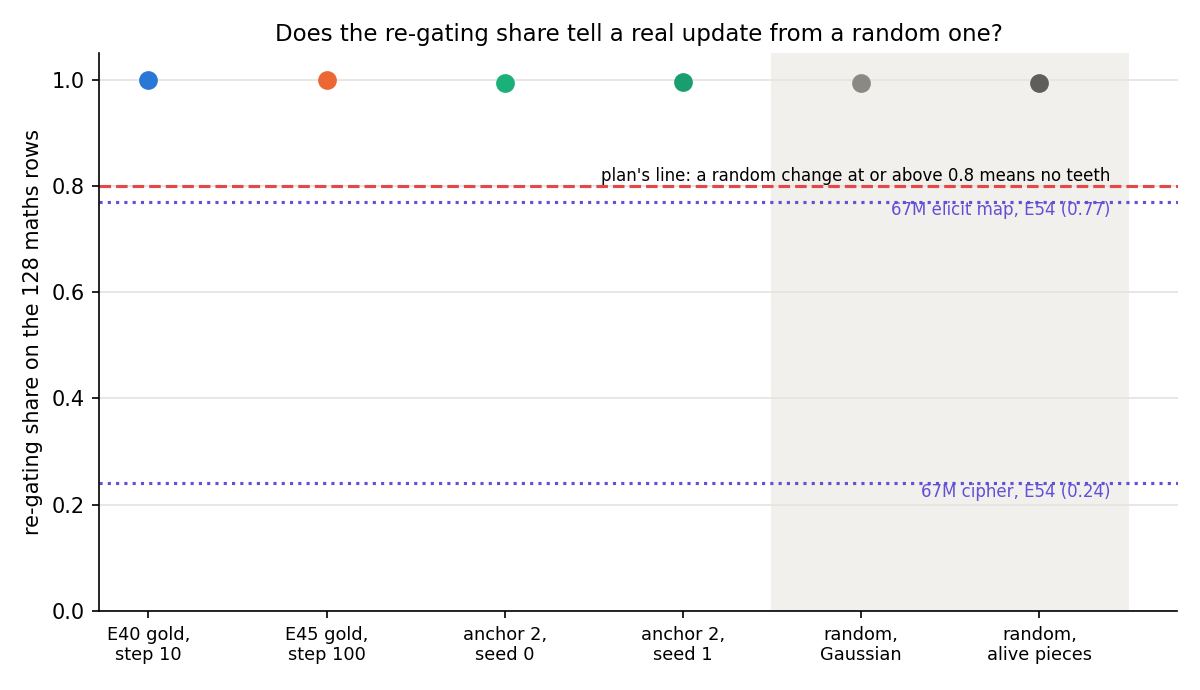

                 state |        re-gating share |      95% row bootstrap
     E40 gold, step 10 |                 0.9993 |       [0.9991, 0.9994]
    E45 gold, step 100 |                 0.9995 |       [0.9993, 0.9997]
      anchor 2, seed 0 |                 0.9927 |       [0.9920, 0.9934]
      anchor 2, seed 1 |                 0.9950 |       [0.9944, 0.9955]
      random, Gaussian |                 0.9940 |       [0.9933, 0.9948]
  random, alive pieces |                 0.9928 |       [0.9916, 0.9940]


In [2]:
display(Image(F / "regating_share.png"))
table(["state", "re-gating share", "95% row bootstrap"],
      [[NAME[n], f"{s['maths']['regating']:.4f}", "[{:.4f}, {:.4f}]".format(*s["maths"]["boot95"])] for n, s in STATE.items()])

**Reading it.** No. Every change, real or random, reads a re-gating share between 0.993 and 0.9995. That is far above
the 0.8 line at which the plan called the share toothless. On the 67M model the same share separated an elicited map
at 0.77 from a cipher at 0.24; here both random changes sit with the real updates. Recomputing the masks on the changed
model's activations recovers almost all of any change, so the share measures "Γ follows the activations".

## Does the direct share separate the updates from random changes of their size?

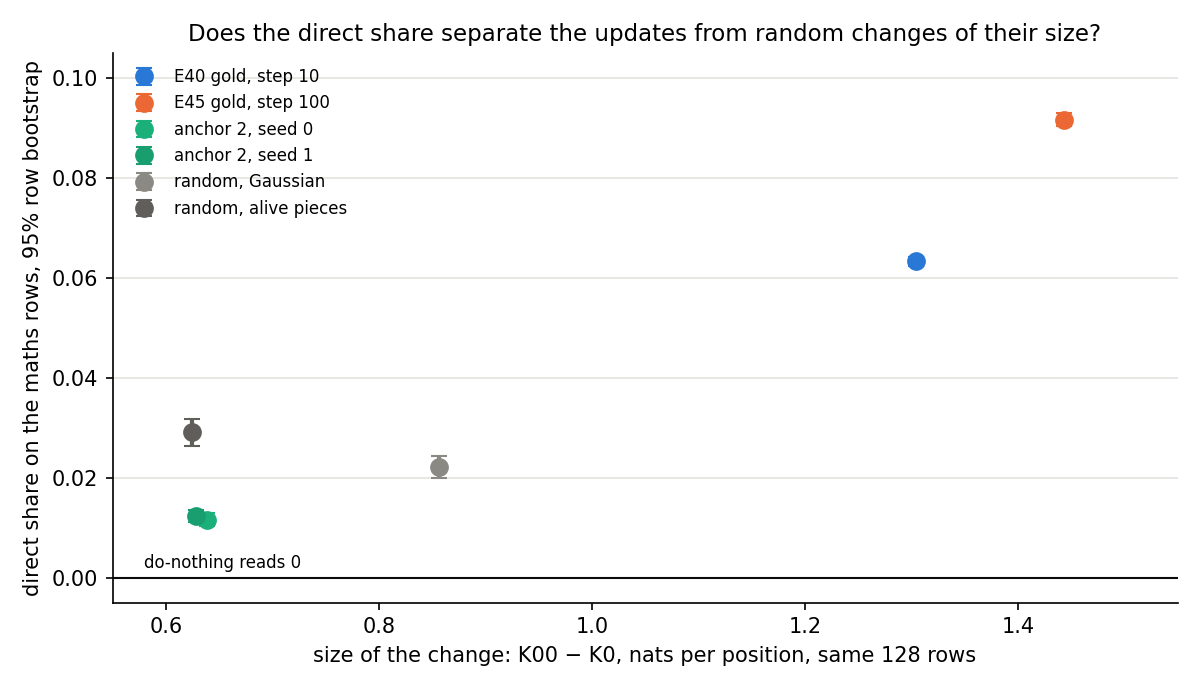

                 state |         size, K00 − K0 |           direct share |      95% row bootstrap
      random, Gaussian |                  0.857 |                 0.0221 |       [0.0199, 0.0243]
  random, alive pieces |                  0.625 |                 0.0291 |       [0.0264, 0.0318]
     E40 gold, step 10 |                  1.304 |                 0.0633 |       [0.0624, 0.0642]
    E45 gold, step 100 |                  1.444 |                 0.0917 |       [0.0904, 0.0930]
      anchor 2, seed 0 |                  0.638 |                 0.0116 |       [0.0103, 0.0129]
      anchor 2, seed 1 |                  0.628 |                 0.0123 |       [0.0111, 0.0135]

            difference |                  value |      95% row bootstrap
E40 gold, step 10 − random, Gaussian |                +0.0412 |     [+0.0388, +0.0436]
E40 gold, step 10 − random, alive pieces |                +0.0342 |     [+0.0313, +0.0370]
E45 gold, step 100 − random, Gaussian |                +0.0696

In [3]:
display(Image(F / "direct_share.png"))
b = J["boot_direct"]
table(["state", "size, K00 − K0", "direct share", "95% row bootstrap"],
      [[NAME[n], f"{size(n):.3f}", f"{v['direct']:.4f}", "[{:.4f}, {:.4f}]".format(*v["boot95"])] for n, v in b["maths"].items()])
print()
table(["difference", "value", "95% row bootstrap"],
      [[" − ".join(NAME[x] for x in k.split("-")), f"{v['gap']:+.4f}", "[{:+.4f}, {:+.4f}]".format(*v["boot95"])] for k, v in b["minus_control"].items()])

**Reading it.** The maths fine-tunes read above the random changes, but they are also the largest changes. Gold reads
0.092, three to four times the random changes; E40 reads 0.063, two to three times. Among the four real updates the
direct share rises with size, and gold is about twice the random changes' size. Anchor 2, matched in size to the
alive-pieces change, reads below it: 0.012 against 0.029.

Gold's interval and the random changes' do not share one interval, so the decision file's condition for closing D3
now is not met. But the row bootstrap covers only the choice of rows. The two random changes differ by 0.007, more
than their intervals allow, so 0.007 is the practical noise floor. The smallest real-minus-random gap, 0.034, is
about five times it. The verdict holds; whether it is size or kind is open until a dose check.

## Do the switched-on sets clear the filed floor?

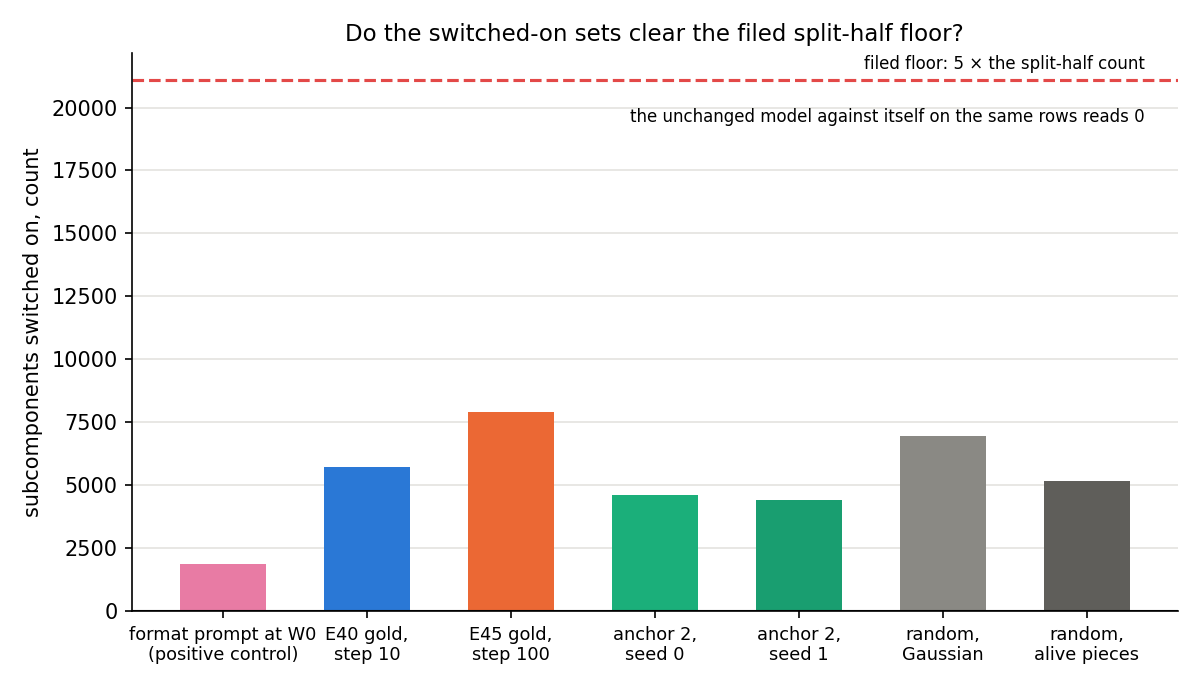

In [4]:
display(Image(F / "switched_on.png"))

**Reading it.** No set clears it, the format prompt included. The floor is five times the number of subcomponents
switched on between two halves of the maths rows, so it measures how gating differs between different rows. The
comparison it guards is two models on the same rows, where the unchanged model against itself reads exactly 0. The
floor is the wrong noise, and every row built on the switched-on sets comes back unscored as filed.

## Is the overlap with each reference set special to real updates?

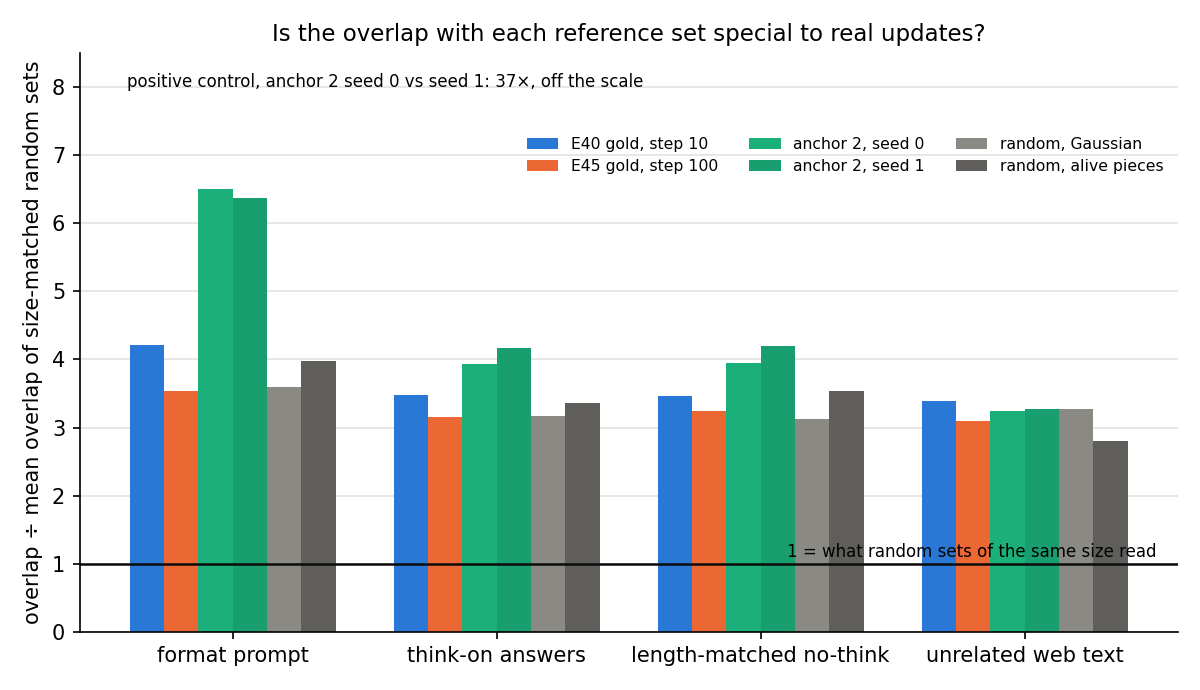

In [5]:
display(Image(F / "overlap_excess.png"))

**Reading it.** Mostly no. Every switched-on set overlaps every reference three to four times more than random sets
of its size, and the random changes sit with E40 and gold everywhere. The exception is anchor 2 on the format prompt's
set: 6.4 to 6.5 times on both seeds, against 3.5 to 4.2 for every other change. It is an observation, not a score,
and it runs against the filed expectation that anchor 2 sits at chance there.

Why every change reads three to four times chance is not measured. The thinking set reads the same as the
length-matched set for every change, so it reads maths context, not thinking, and is not used for D3. The filed excess
in standard deviations grows with the reference set's size, so its ordering only repeats the sets' sizes.

## Does the split put more energy on subcomponents gated on at the original model than a random update's split?

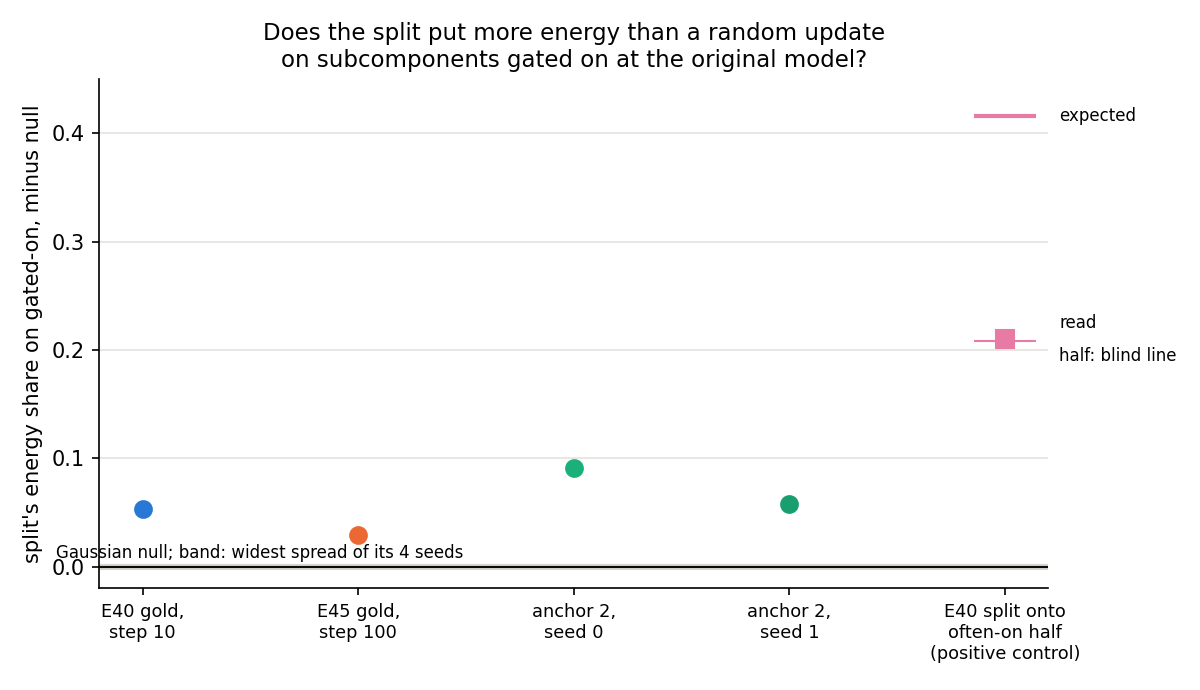

In [6]:
display(Image(F / "placement.png"))

**Reading it.** Slightly, for every update, but the positive control sits at the blind line. Each update's split puts
0.03 to 0.09 more of its energy on subcomponents gated on at the original model than a Gaussian update's split does.
The positive control clears the blind line by 0.0023, less than the 0.0038 spread of the null's seeds. The two
anchor-2 seeds differ by 0.033, as much as the states differ from one another.

## Where does δW sit?

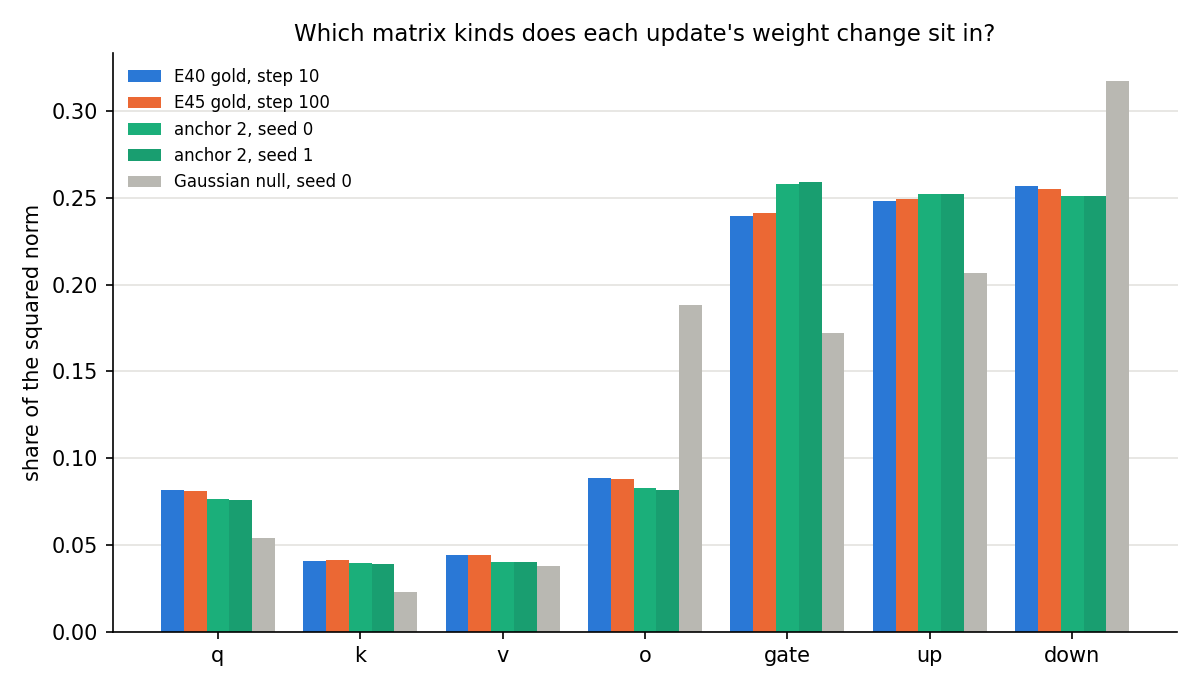

In [7]:
display(Image(F / "where_kind.png"))

**Reading it.** All four updates spread their change over matrix kinds in nearly the same way, about a quarter in each
MLP matrix. The Gaussian null puts more into the attention output and MLP down matrices. The updates are also
lower-rank than the null, a median effective rank of 848 to 1,069 per matrix against 1,649. Anchor 2's change sits in
the late layers; gold's is nearly flat across layers. This row is descriptive.

## What we learned

At Qwen3-1.7B scale, any reading that lets Γ recompute its masks on the changed model reads the same for real and
random changes. So re-gating, as these rows define it, cannot carry the question of whether post-training strengthens
what exists or builds something new. The direct share is the one route-split number that separates real updates from
random changes, but the separation may be size. Whether it tells the two kinds of update apart needs anchor 1 at a
size matched to anchor 2.

## How compelling is the evidence

The no-teeth result is strong: two random changes of different kinds, both at 0.99, with tight intervals. The
direct-share gap is about five times the spread between the two random changes, but it is confounded with size. One
model, one decomposition, one draw per random control. The direct share is blind to whatever the split leaves in Δ.
The switching and overlap rows have no usable floor or null as filed.

## Surprises

- The random changes' overlap with the thinking set was expected near 0 and reads about 3.3 times chance.
- Anchor 2 overlaps the format prompt's set 6.4 to 6.5 times chance, against an expected "at chance".
- The format prompt fails to clear the filed floor, and E40's re-gating share reads 0.999, above the expected range.
- Anchor 2's direct share sits below both random changes on the maths rows. No prediction covered it.

## What next

- A dose check of the direct share first, on saved states: a random change scaled to gold's size. If its direct share
  rises to gold's level, the separation is size, not kind.
- Stage D needs size matching too. Anchor 1 reached maths KL 0.33 with a weight change of norm 3.14, against anchor 2's
  0.62 and 5.1, so an anchor gap cannot by itself be read as kind. The decision file's option 6, anchor 2's states
  between steps 12 and 100, would find a matched point.
- A same-row floor for the switched-on sets, and overlaps against the random changes' own sets as fold enrichment.

## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| E45 regating_share | anchor 1 ≥ 0.5, anchor 2 below | anchor 2 0.993, 0.995 | unscored: anchor 1 never matched |
| E45 behaviour_kept | anchor 1 ≥ 0.8, anchor 2 below | anchor 2 0.953, 0.963 | unscored: anchor 1 never matched |
| E45 placement | anchor 1 above anchor 2 | anchor 2 0.091, 0.058 | unscored: anchor 1 never matched |
| prompt_overlap | anchor 1 above q99, anchor 2 at or below q95 | prompt set below floor | unscored |
| think_overlap | anchor 2 at or below q95 | 965, 960 against q95 268, 253 | unscored |

## Departures from the literature

- VPD computes masks from the model being decomposed; two cells here use masks from the original model's activations.
- The route split and its shares are this project's; no source defines them.
- "Gated on" adds "on at least 1% of positions" to VPD's alive threshold.
- Thinking answers use the model card's sampling, capped at 2048 new tokens against its recommended 32,768.
- The unrelated set is raw web text, not chat.
- KL to the start is teacher-forced on fixed rows, not on the model's own samples as in RL's Razor; the size yardstick
  K00 − K0 is this project's.
- E40's recipe has no learning-rate warm-up, unlike standard recipes and E45's.
- Effective rank is Roy and Vetterli's, on the raw δW. Gaussian nulls are seeded per site, unlike E44.
- Bootstrap intervals are plain percentile intervals over row resamples.

## Not run

- Stage D and the scoring; the decision file's option 6, anchor 2's intermediate states.
- A dose check of the direct share, and a KL to the start on the same rows for all six states.
- More than one draw per random control; a positive control for the direct share; a second gold seed.
- The random changes on own rows, and their placement; a bootstrap of the placement excess.
- The overlap bootstrap; a test of why every change reads three to four times chance.
- A same-row floor for the switched-on sets, and matched random-set overlaps.

## Provenance

MATS cluster L40s, $0. Slurm jobs 46297, 46331, 46345, 46350 and 46394, for Stages A to C in order. Results
`experiments/qwen_reading/results/`, figures from `experiments/qwen_reading/plot.py`, bootstrap from
`experiments/qwen_reading/boot_direct.py`.